# Dimensionality Reduction with PCA, t-SNE and UMAP

<!--<badge>--><a href="https://colab.research.google.com/github/kuennethgroup/ml_in_ms_wt26/blob/main/04_ex/dimensionality_reduction_pca_tsne_umap.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a><!--</badge>-->

Materials datasets often have many features/inputs (compositions, fingerprints, process parameters, spectra, ...). Dimensionality reduction maps such data to a smaller number of dimensions while keeping as much of the relevant information as possible.

In this notebook we compare three popular methods:

| Method | Type | Keeps | Can transform new data? | Main use |
|---|---|---|---|---|
| **PCA** (Principal Component Analysis) | linear | global variance | yes | EDA, feature extraction, noise reduction |
| **t-SNE** (t-distributed Stochastic Neighbor Embedding) | non-linear | local neighborhoods | **no** | visualization |
| **UMAP** (Uniform Manifold Approximation and Projection) | non-linear | local + (some) global structure | yes | visualization, feature extraction |

We use them for three typical tasks:

1. Exploratory data analysis (EDA): look at high-dimensional data in 2D
2. Feature extraction: compress features before training a model
3. Noise reduction: remove noise by keeping only the most important components

Throughout the notebook you will find 🧑‍💻 Exercises. Solve them before you move on.

In [8]:
# Import the necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

# Set style for visualizations
sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.size": 12})

## Penguins Dataset

We use the Palmer Penguins dataset. It has measurements of three penguin species from the Palmer Archipelago, Antarctica.

### The dataset has:
- 3 penguin species (Adelie, Chinstrap, Gentoo)
- Measurements of bill length, bill depth, flipper length, and body mass
- The island where each penguin was observed
- Sex and year of observation

<img src="https://raw.githubusercontent.com/allisonhorst/palmerpenguins/c19a904462482430170bfe2c718775ddb7dbb885/man/figures/lter_penguins.png" alt="Three penguin species" width="500"/>

<img src="https://github.com/allisonhorst/palmerpenguins/blob/c19a904462482430170bfe2c718775ddb7dbb885/man/figures/culmen_depth.png?raw=true" alt="Bill dimensions diagram" width="500"/>

## 1. Loading and Cleaning the Data

In [9]:
df_penguins = pd.read_csv(
    "https://raw.githubusercontent.com/allisonhorst/palmerpenguins/c19a904462482430170bfe2c718775ddb7dbb885/inst/extdata/penguins.csv"
)

# Remove rows with missing values
print(f"Shape before dropping missing values: {df_penguins.shape}")
df_penguins = df_penguins.dropna().reset_index(drop=True)
print(f"Shape after dropping missing values: {df_penguins.shape}")

display(df_penguins.head())
display(df_penguins.species.value_counts())

Shape before dropping missing values: (344, 8)
Shape after dropping missing values: (333, 8)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007
4,Adelie,Torgersen,39.3,20.6,190.0,3650.0,male,2007


species
Adelie       146
Gentoo       119
Chinstrap     68
Name: count, dtype: int64

### Scaling the features

PCA, t-SNE and UMAP all work with distances or variances, so features with large values (e.g., `body_mass_g` ≈ 4000) would dominate features with small values (e.g., `bill_depth_mm` ≈ 17). We therefore standardize all features to zero mean and unit variance with `StandardScaler`.

In [10]:
# The numerical features we use for dimensionality reduction
features = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g",
]

X = df_penguins[features].values
y = df_penguins["species"].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Data shape: {X_scaled.shape}  (samples, features)")
print(f"Mean after scaling: {X_scaled.mean(axis=0).round(2)}")
print(f"Std after scaling:  {X_scaled.std(axis=0).round(2)}")

Data shape: (333, 4)  (samples, features)
Mean after scaling: [-0. -0.  0. -0.]
Std after scaling:  [1. 1. 1. 1.]


# 1. Exploratory data analysis (EDA) and visualization

We can look at all pairs of features in a pairplot. But a pairplot of 100 features is too large (4950 panels). Dimensionality reduction gives us one 2D picture of all features at once. That's the goal.

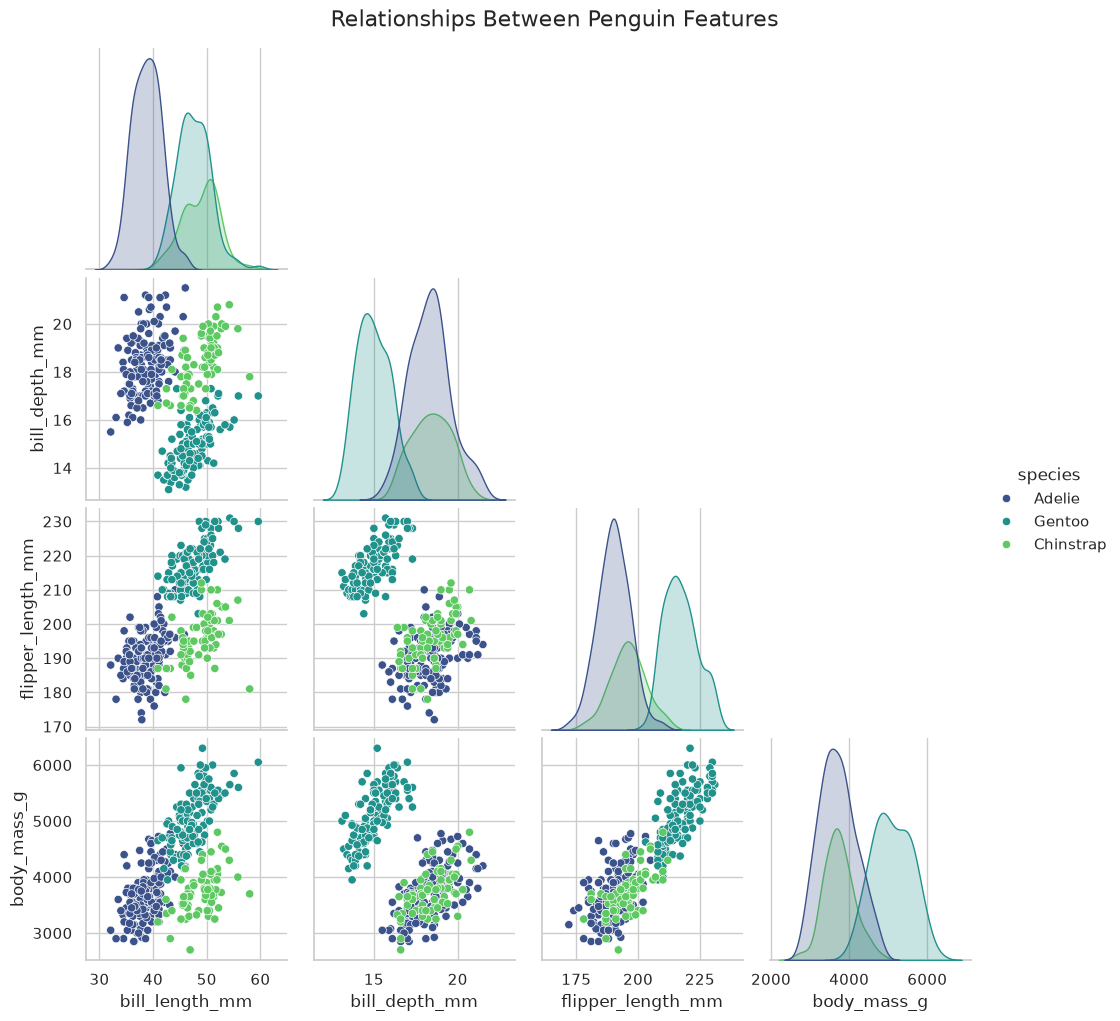

In [11]:
# Pairplot of all feature pairs
pairplot = sns.pairplot(
    df_penguins[features + ["species"]],
    hue="species",
    palette="viridis",
    corner=True,
)
pairplot.figure.suptitle("Relationships Between Penguin Features", y=1.02, fontsize=16)
plt.show()

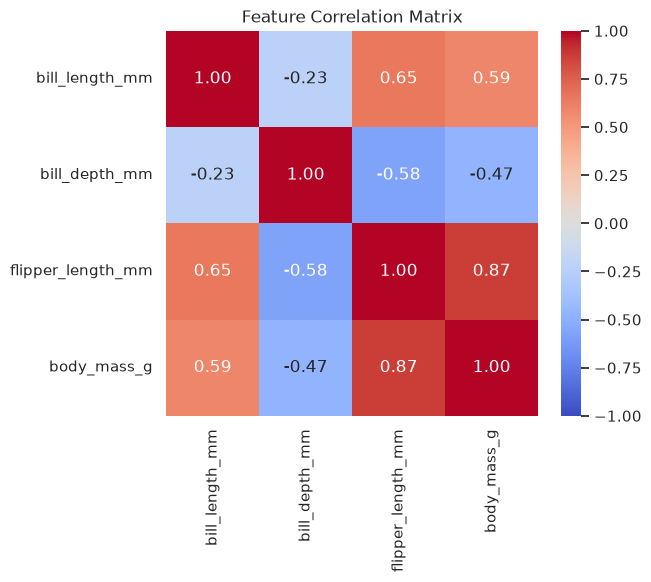

In [39]:
# Correlation matrix: strongly correlated features carry redundant information,
# which is exactly what PCA can compress
plt.figure(figsize=(6, 5))
sns.heatmap(
    df_penguins[features].corr(), # computes pariwise correlation, default is Pearson correlation
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
)
plt.title("Feature Correlation Matrix")
plt.show()

## 1.1 Principal Component Analysis (PCA)

PCA finds new axes, the !principal components (PCs)!, that are linear combinations of the original features:

$$\text{PC}_k = w_{k,1} \cdot x_1 + w_{k,2} \cdot x_2 + \dots + w_{k,n} \cdot x_n$$

- PC1 points in the direction of the largest variance in the data, PC2 in the direction of the largest remaining variance (orthogonal to PC1), and so on.
- The weights $w_{k,i}$ are called loadings. They tell us how much each original feature contributes to a component, so they show feature importance.
- `explained_variance_ratio_` tells us how much of the total variance each component captures.

We first fit PCA with all 4 components to see how the variance is distributed.

In [ ]:
# all components
pca = PCA() 
X_pca = pca.fit_transform(X_scaled)

explained = pca.explained_variance_ratio_
for i, ev in enumerate(explained):
    print(f"PC{i + 1}: {ev:6.1%} of variance (cumulative: {explained[: i + 1].sum():6.1%})")

PC1:  68.6% of variance (cumulative:  68.6%)
PC2:  19.5% of variance (cumulative:  88.1%)
PC3:   9.2% of variance (cumulative:  97.3%)
PC4:   2.7% of variance (cumulative: 100.0%)


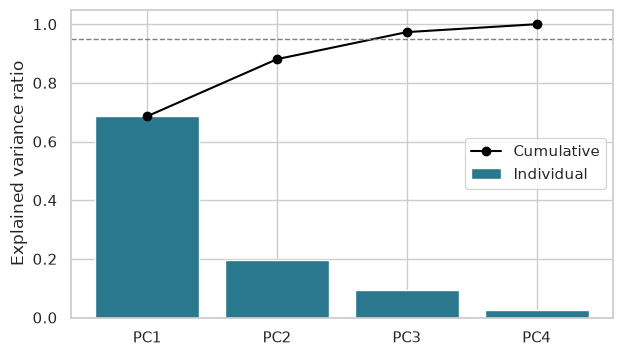

In [ ]:
# Scree plot: explained variance per component + cumulative variance
pc_labels = [f"PC{i + 1}" for i in range(len(explained))]

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(pc_labels, explained, color=sns.color_palette("viridis", 4)[1], label="Individual")
ax.plot(pc_labels, np.cumsum(explained), "o-", color="black", label="Cumulative")
ax.axhline(0.95, color="gray", ls="--", lw=1)
ax.text(3.05, 0.95, "95%", va="center", color="gray")
ax.set_ylabel("Explained variance ratio")
ax.set_ylim(0, 1.05)
ax.legend()
plt.show()

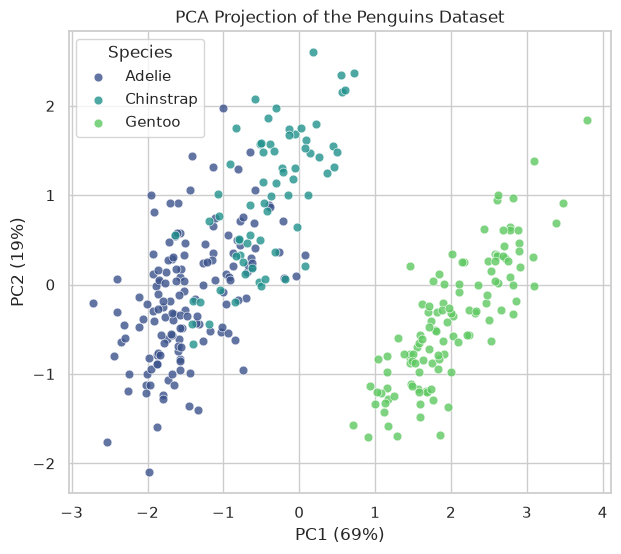

In [15]:
# 2D PCA projection, colored by species
species_colors = dict(zip(sorted(df_penguins.species.unique()), sns.color_palette("viridis", 3)))


def plot_embedding(embedding, title, ax=None, xlabel="Dim 1", ylabel="Dim 2", labels=y):
    """Scatter plot of a 2D embedding colored by species."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 6))
    for species, color in species_colors.items():
        idx = labels == species
        ax.scatter(
            embedding[idx, 0],
            embedding[idx, 1],
            color=color,
            label=species,
            s=40,
            alpha=0.8,
            edgecolor="white",
            linewidth=0.5,
        )
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend(title="Species")
    return ax


plot_embedding(
    X_pca[:, :2],
    "PCA Projection of the Penguins Dataset",
    xlabel=f"PC1 ({explained[0]:.0%})",
    ylabel=f"PC2 ({explained[1]:.0%})",
)
plt.show()

### Feature importance: PCA loadings

The loadings are stored in `pca.components_` (shape: `n_components × n_features`). A large absolute value means that the feature contributes strongly to that component. The sign tells the direction: features with the same sign increase together along the component.

,PC1,PC2,PC3,PC4
bill_length_mm,0.454,0.600,0.642,-0.145
bill_depth_mm,-0.399,0.796,-0.426,0.160
flipper_length_mm,0.577,0.006,-0.236,0.782
body_mass_g,0.550,0.076,-0.592,-0.585


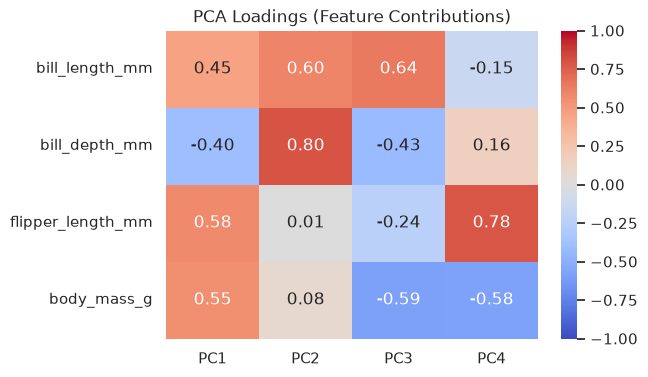

In [16]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=features,
    columns=pc_labels,
)
display(loadings.round(3))

plt.figure(figsize=(6, 4))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("PCA Loadings (Feature Contributions)")
plt.show()

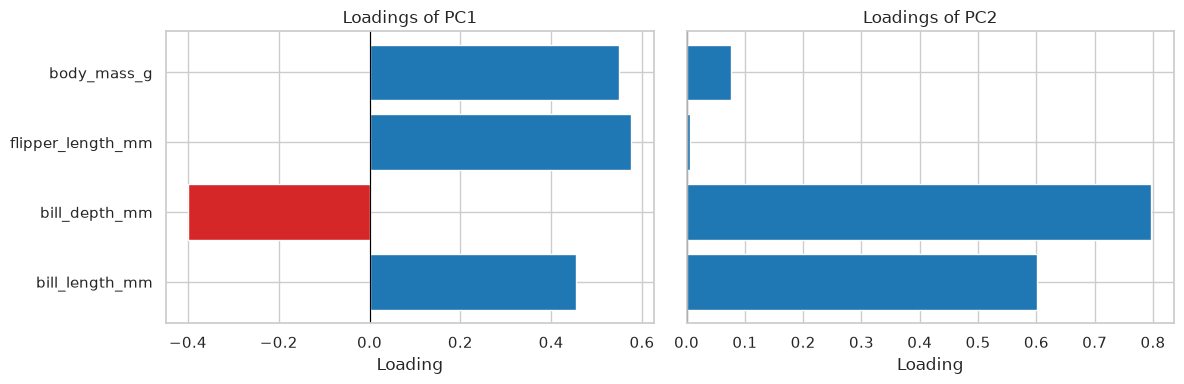

In [17]:
# Bar plots of the loadings for PC1 and PC2
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, pc in zip(axes, ["PC1", "PC2"]):
    colors = ["tab:red" if v < 0 else "tab:blue" for v in loadings[pc]]
    ax.barh(features, loadings[pc], color=colors)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(f"Loadings of {pc}")
    ax.set_xlabel("Loading")
plt.tight_layout()
plt.show()

A single number per feature is often handy. A common choice is to weight the squared loadings by the explained variance of each component and sum them up. This gives the share of the total (scaled) variance that each feature contributes to the selected components.

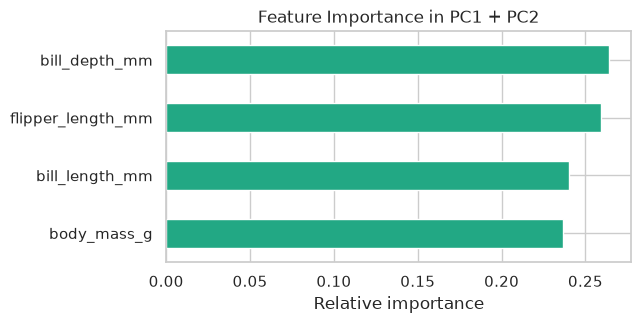

In [18]:
def pca_feature_importance(pca, feature_names, n_components):
    """Variance-weighted squared loadings, summed over the first n_components."""
    weights = pca.explained_variance_ratio_[:n_components]
    contrib = (pca.components_[:n_components] ** 2).T @ weights
    return pd.Series(contrib / contrib.sum(), index=feature_names).sort_values()


importance = pca_feature_importance(pca, features, n_components=2)
importance.plot.barh(figsize=(6, 3), color=sns.color_palette("viridis", 4)[2])
plt.xlabel("Relative importance")
plt.title("Feature Importance in PC1 + PC2")
plt.show()

### Biplot

A **biplot** shows the samples (points) and the loadings (arrows) together. An arrow shows in which direction a feature increases in the PCA plot. Arrows pointing in the same direction belong to correlated features.

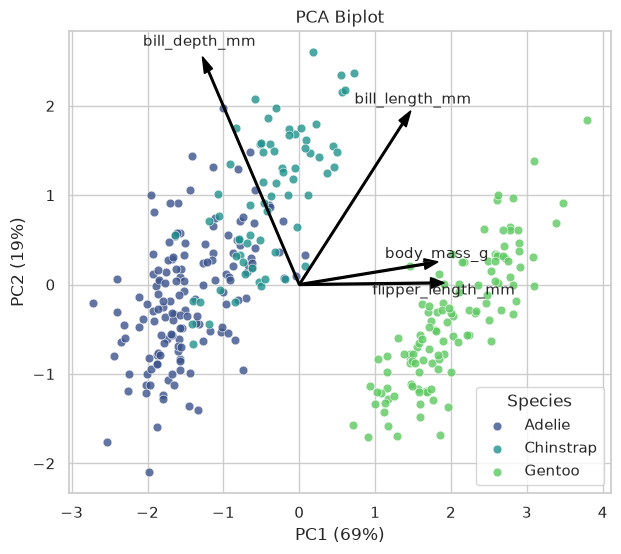

In [45]:
ax = plot_embedding(
    X_pca[:, :2],
    "PCA Biplot",
    xlabel=f"PC1 ({explained[0]:.0%})",
    ylabel=f"PC2 ({explained[1]:.0%})",
)

arrow_scale = 3  # scales the arrows for better visibility
for feature, (lx, ly) in zip(features, pca.components_[:2].T):
    ax.arrow(0, 0, lx * arrow_scale, ly * arrow_scale, color="black", width=0.02, head_width=0.12)
    va = "bottom" if ly > 0.05 else "top"
    ax.text(lx * arrow_scale * 1.1, ly * arrow_scale * 1.1, feature, fontsize=11, ha="center", va=va)
plt.show()

### Exercise

1. How many components do you need to explain at least 95% of the variance?
2. Look at the loadings of PC1. All four features have a similar weight, but `bill_depth_mm` has the opposite sign. Give PC1 a physical name (Hint: think about "size"). What does a penguin with a large PC1 value look like?
3. Which feature dominates PC2? Which species is separated from the others along PC1, and which along PC2?
4. Why do scale features? Repeat PCA on the *unscaled* data `X`. Print `explained_variance_ratio_` and the loadings. Which feature dominates PC1 now and why?

In [20]:
# Your code here (Exercise 1.4: PCA on unscaled data)

## 1.2 t-SNE

t-SNE is a non-linear method designed for visualization. It turns distances into probabilities that two points are neighbors and then places the points in 2D so that these neighbor probabilities are kept.

Important properties:
- It keeps local neighborhoods well, but distances *between* clusters and cluster sizes are not meaningful.
- The most important parameter is the perplexity (≈ number of effective neighbors, typically 5–50).
- The result depends on the random seed.
- t-SNE has no `transform` method: you cannot project new data points into an existing t-SNE map.

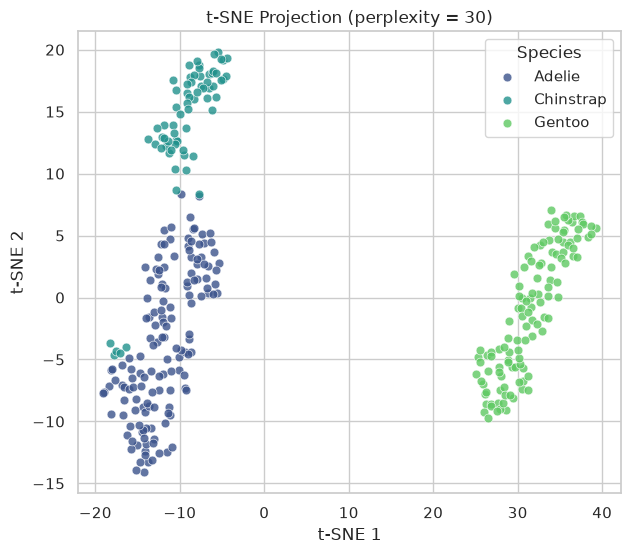

In [21]:
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
X_tsne = tsne.fit_transform(X_scaled)

plot_embedding(X_tsne, "t-SNE Projection (perplexity = 30)", xlabel="t-SNE 1", ylabel="t-SNE 2")
plt.show()

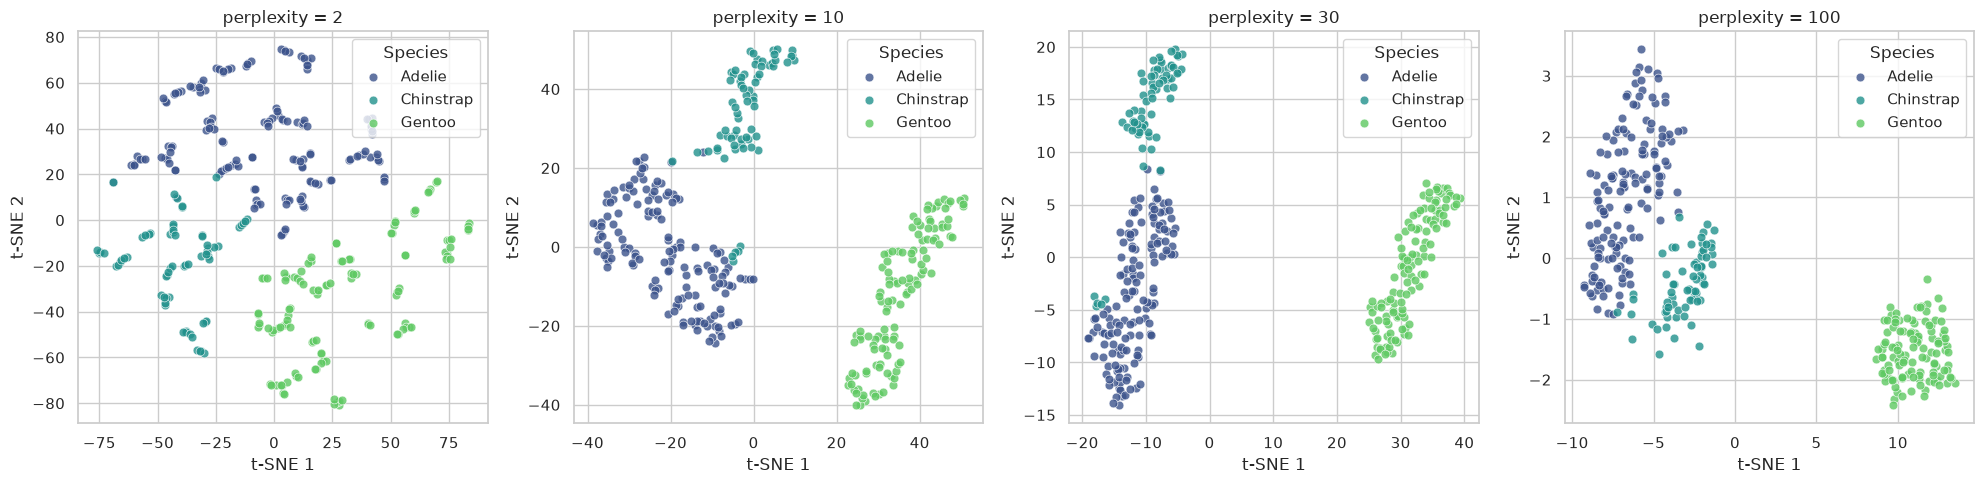

In [22]:
# Effect of the perplexity
perplexities = [2, 10, 30, 100]
fig, axes = plt.subplots(1, len(perplexities), figsize=(20, 5))
for ax, perp in zip(axes, perplexities):
    emb = TSNE(n_components=2, perplexity=perp, random_state=42).fit_transform(X_scaled)
    plot_embedding(emb, f"perplexity = {perp}", ax=ax, xlabel="t-SNE 1", ylabel="t-SNE 2")
plt.tight_layout()
plt.show()

###  Exercise

1. Describe how the plot changes with the perplexity. Which value gives many small, artificial clusters?
2. Run t-SNE with `perplexity=30` three times with different `random_state` values. Does the overall picture (which species are close) stay the same? Do the positions and orientations stay the same?

In [23]:
# Your code here (Exercise 2)

## 1.3 UMAP

UMAP is also non-linear. It builds a neighbor graph in the original space and finds a low-dimensional layout with a similar graph. Compared to t-SNE, UMAP:
- is usually faster for large datasets,
- tends to keep more of the global structure,
- has a `transform` method, so new data can be projected into an existing map.

Main parameters:
- **n_neighbors**: balance between local (small values) and global (large values) structure (default = 15)
- **min_dist**: how tightly points may be packed together (default = 0.1)

/home/chris/courses/ml-in-ms-wt26/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


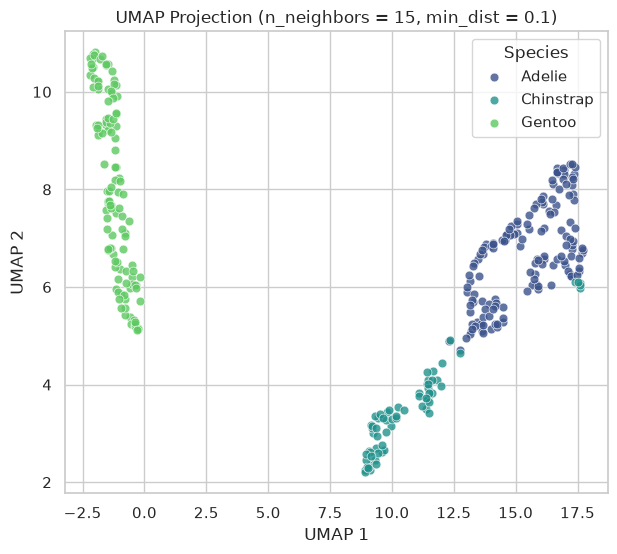

In [24]:
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=42)
X_umap = reducer.fit_transform(X_scaled)

plot_embedding(X_umap, "UMAP Projection (n_neighbors = 15, min_dist = 0.1)", xlabel="UMAP 1", ylabel="UMAP 2")
plt.show()

/home/chris/courses/ml-in-ms-wt26/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/chris/courses/ml-in-ms-wt26/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/home/chris/courses/ml-in-ms-wt26/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/chris/courses/ml-in-ms-wt26/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/chris/courses/ml-in-ms-wt26/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/chris/courses/ml-in-ms-wt26/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


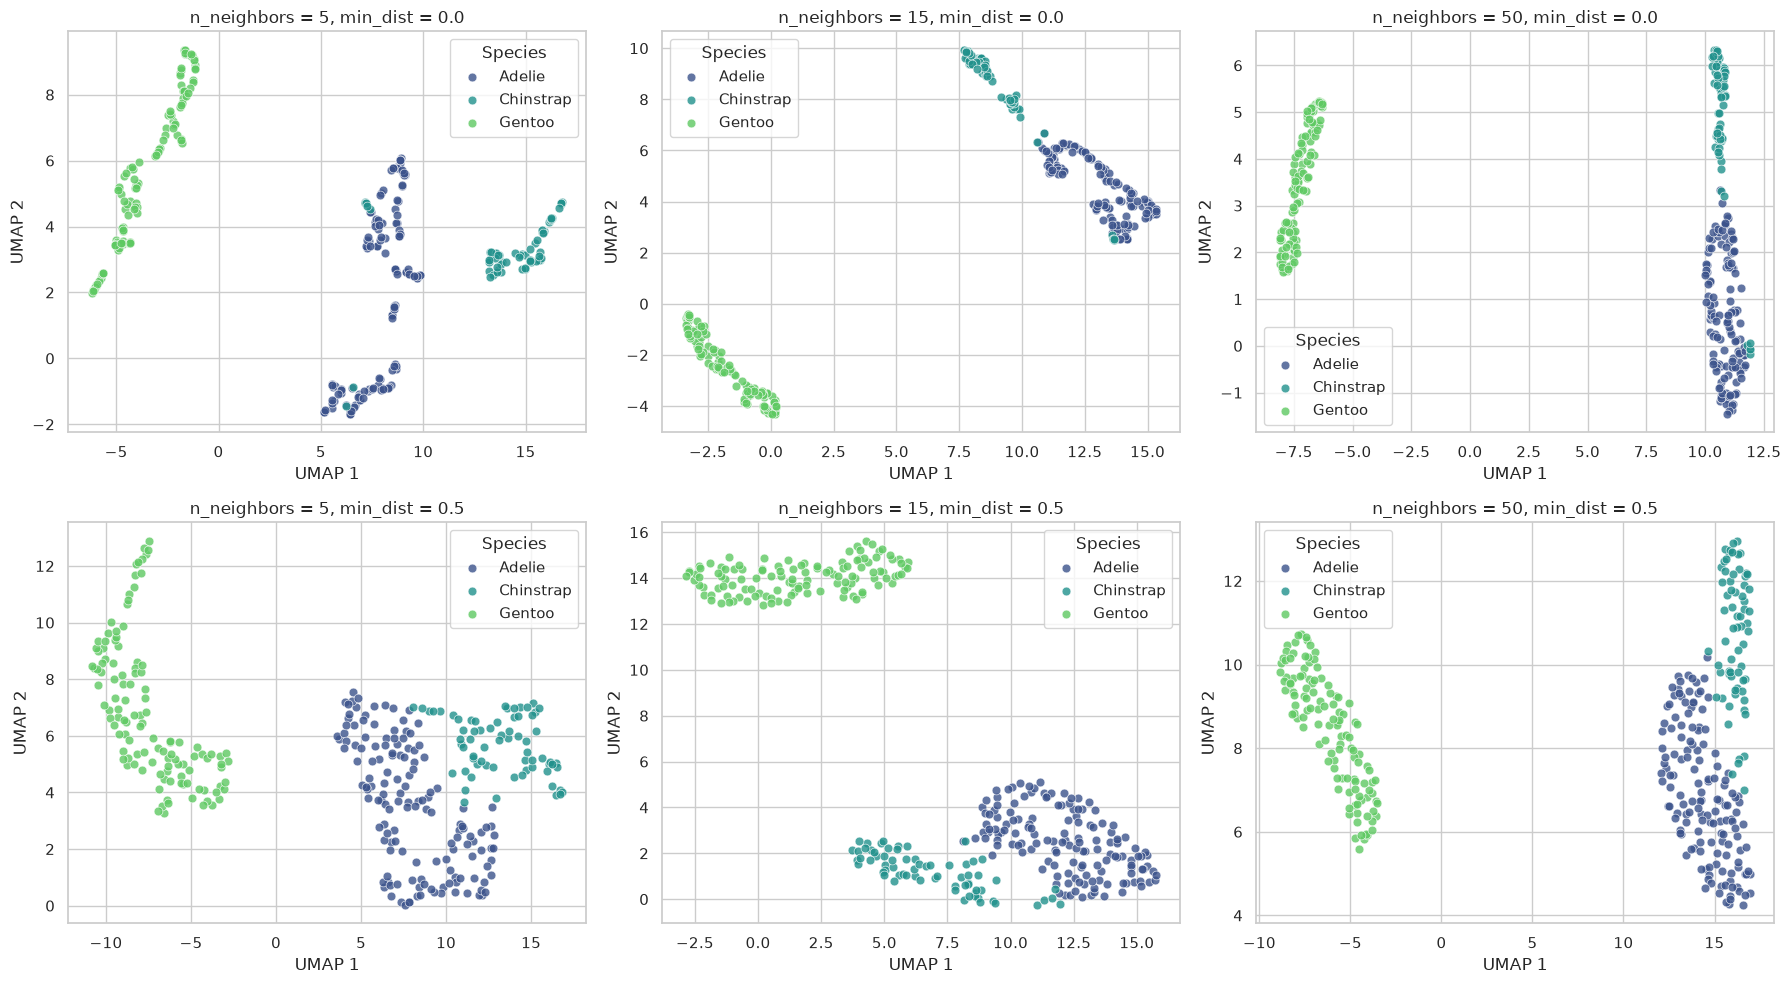

In [25]:
# Effect of n_neighbors and min_dist
n_neighbors_list = [5, 15, 50]
min_dist_list = [0.0, 0.5]

fig, axes = plt.subplots(len(min_dist_list), len(n_neighbors_list), figsize=(18, 10))
for i, min_dist in enumerate(min_dist_list):
    for j, n_neighbors in enumerate(n_neighbors_list):
        emb = umap.UMAP(n_neighbors=n_neighbors, min_dist=min_dist, random_state=42).fit_transform(X_scaled)
        plot_embedding(
            emb,
            f"n_neighbors = {n_neighbors}, min_dist = {min_dist}",
            ax=axes[i, j],
            xlabel="UMAP 1",
            ylabel="UMAP 2",
        )
plt.tight_layout()
plt.show()

## 1.4 Comparison of PCA, t-SNE and UMAP

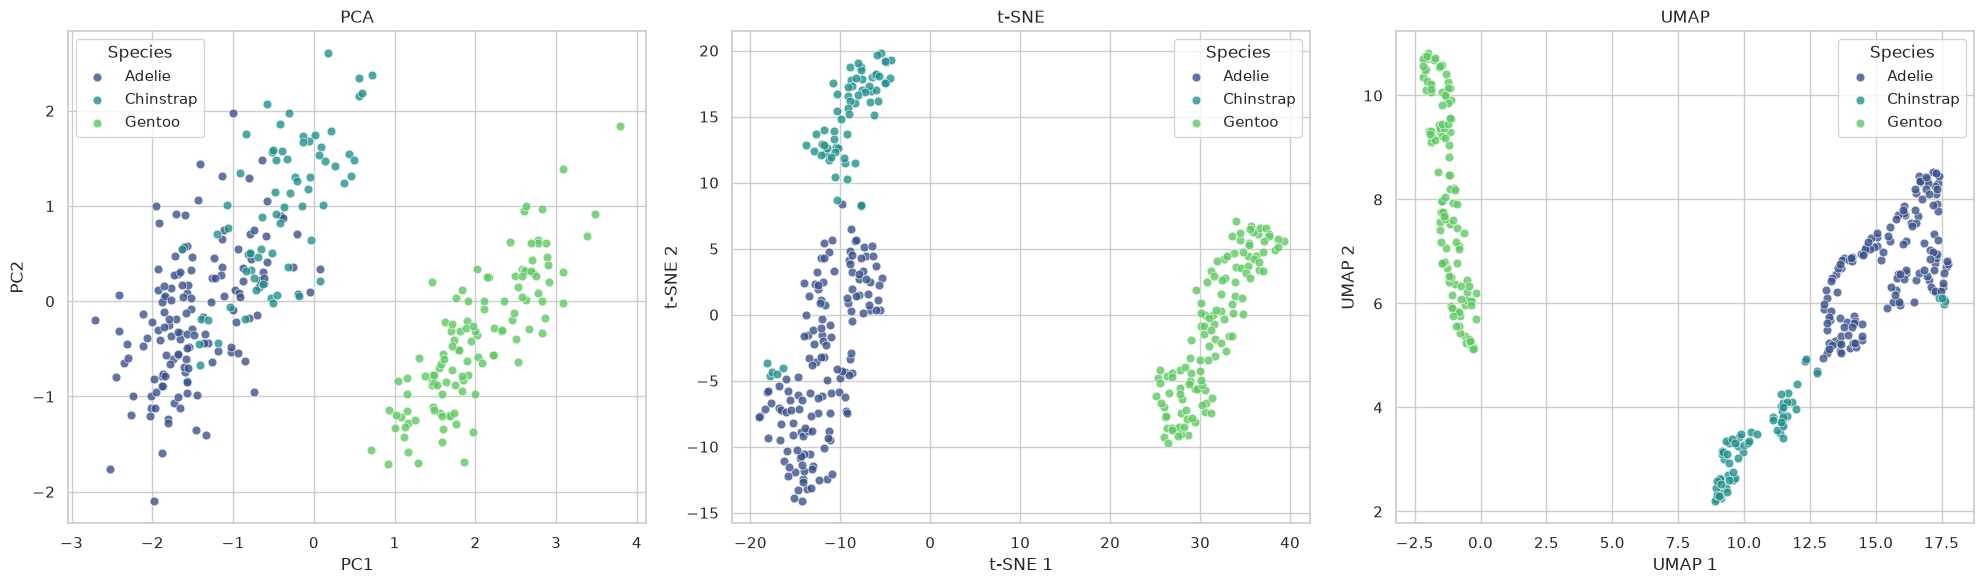

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
plot_embedding(X_pca[:, :2], "PCA", ax=axes[0], xlabel="PC1", ylabel="PC2")
plot_embedding(X_tsne, "t-SNE", ax=axes[1], xlabel="t-SNE 1", ylabel="t-SNE 2")
plot_embedding(X_umap, "UMAP", ax=axes[2], xlabel="UMAP 1", ylabel="UMAP 2")
plt.tight_layout()
plt.show()

- All three methods separate Gentoo clearly from Adelie and Chinstrap.
- PCA is linear: its axes have a meaning (the loadings), and distances in the plot are directly related to distances in the scaled feature space.
- t-SNE and UMAP form tighter clusters and separate Adelie and Chinstrap better, but their axes have **no** physical meaning.

###  Exercise

Dimensionality reduction is unsupervised: it never sees the species label. We only use the labels for coloring.

1. Color the PCA, t-SNE and UMAP plots by **sex** instead of species (Hint: `sns.scatterplot(x=..., y=..., hue=df_penguins["sex"], style=df_penguins["species"])`). Do you find sub-clusters inside the species clusters?
2. Color the plots by **island**. Do Adelie penguins from different islands form separate groups?
3. Look for points that sit inside the "wrong" species cluster. Find their row index in `df_penguins` and look at their measurements. Are they possible outliers or mislabeled samples?

In [27]:
# Your code here (Exercise 3)

---
# 2: Preprocessing for Machine Learning (Feature Extraction)

Dimensionality reduction can also be used as a preprocessing step before a machine learning model:
- fewer features → faster training and less risk of overfitting
- correlated (redundant) features are combined into uncorrelated components

Important: the reduction must be fitted on the training data only and then applied to the test data. With scikit-learn this is easiest with a `Pipeline`, which also works inside cross-validation.

This is a key difference between the methods:
- PCA and UMAP have a `transform` method → can be used in a pipeline
- t-SNE has no `transform` → it can not be used as a preprocessing step for new data

Train a k-nearest-neighbors classifier to predict the species with 1, 2, 3, or 4 PC.

In [46]:
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

results = []
for n_components in range(1, len(features) + 1):
    model = make_pipeline(
        StandardScaler(),  # fitted on the training folds only
        PCA(n_components=n_components),  # fitted on the training folds only
        KNeighborsClassifier(n_neighbors=5),
    )
    scores = cross_val_score(model, df_penguins[features], y, cv=5)
    results.append({"n_components": n_components, "accuracy": scores.mean(), "std": scores.std()})

df_results = pd.DataFrame(results)
df_results.round(3)

,n_components,accuracy,std
0,1,0.877,0.034
1,2,0.895,0.013
2,3,0.988,0.006
3,4,0.988,0.006


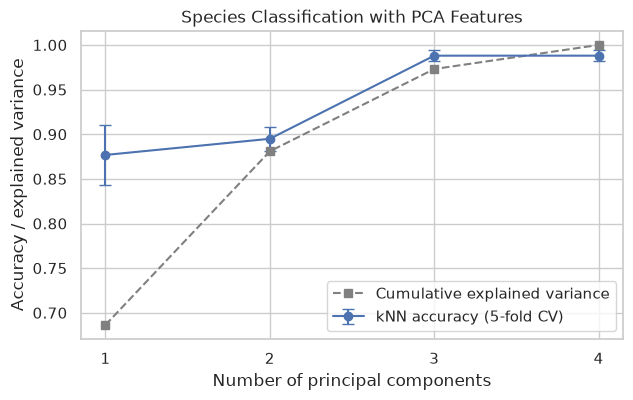

In [29]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(df_results.n_components, df_results.accuracy, yerr=df_results["std"], fmt="o-", capsize=4, label="kNN accuracy (5-fold CV)")
ax.plot(df_results.n_components, np.cumsum(explained), "s--", color="gray", label="Cumulative explained variance")
ax.set_xticks(df_results.n_components)
ax.set_xlabel("Number of principal components")
ax.set_ylabel("Accuracy / explained variance")
ax.set_title("Species Classification with PCA Features")
ax.legend()
plt.show()

PC3 explains only ~9% of the variance, but adding it improves the accuracy a lot. **High variance does not always mean high importance for a prediction task.** PCA is unsupervised and does not know what we want to predict.

### Using a fitted PCA on new data

Because PCA has a `transform` method, we can project new penguins into the existing PCA space, for example, a new penguin measured in the field.

/home/chris/courses/ml-in-ms-wt26/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


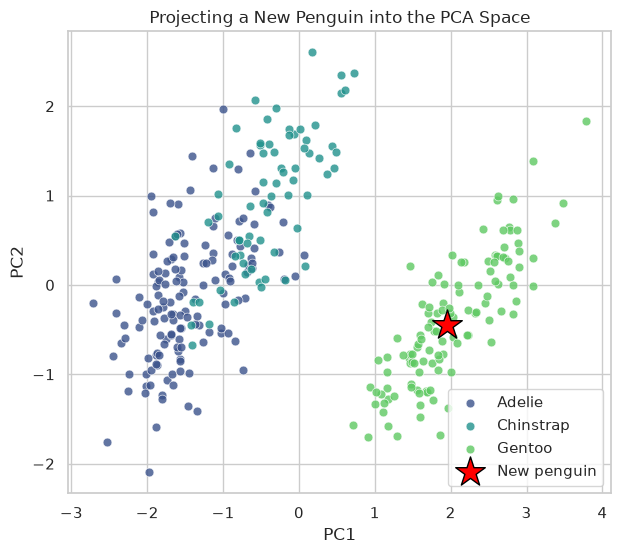

In [30]:
# A new (made-up) penguin
new_penguin = pd.DataFrame(
    [[47.0, 15.0, 215.0, 5200.0]],
    columns=features,
)

# Use the scaler and the PCA fitted above (no refitting!)
new_penguin_pca = pca.transform(scaler.transform(new_penguin))

ax = plot_embedding(X_pca[:, :2], "Projecting a New Penguin into the PCA Space", xlabel="PC1", ylabel="PC2")
ax.scatter(new_penguin_pca[:, 0], new_penguin_pca[:, 1], marker="*", s=500, color="red", edgecolor="black", label="New penguin")
ax.legend()
plt.show()

### Exercise

1. Project the same new penguin into the **UMAP** map with `reducer.transform(...)` and plot it. Which species would you assign it to?
3. Repeat the classification loop above, but predict **sex** (`df_penguins["sex"]`) instead of species. How many components do you need now? Is the result the same as for species?
4. Replace the `KNeighborsClassifier` by `LogisticRegression(max_iter=1000)` (from `sklearn.linear_model`). Does the conclusion change?

In [31]:
# Your code here (Exercise 4)

## Exercise

In this exercise, you'll apply dimensionality reduction to polymer data to discover patterns related to crystallization tendency.

- Load the polymer dataset from the URL: 
   `https://raw.githubusercontent.com/kuennethgroup/materials_datasets/refs/heads/main/polymer_tendency_to_crystalize/polymers_tend_to_crystalize.json`
- Use `pandas.read_json()` to import the data
- Explore the data structure to identify which columns contain fingerprints and crystallization labels
- Follow the above steps to perform PCA, t-SNE and UMAP on the polymer fingerprints and visualize the results. Color the points by crystallization tendency to see if there are any patterns or clusters that emerge.
